In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE


In [2]:
# load + clean
df = pd.concat(pd.read_excel("online_retail_II.xlsx", sheet_name=None).values())
df = df.dropna(subset=["Customer ID"])
df = df[(~df["Invoice"].astype(str).str.startswith("C")) & (df.Quantity > 0) & (df.Price > 0)]
df["Rev"] = df.Quantity * df.Price

In [3]:
# RFM
snap = df.InvoiceDate.max() + pd.Timedelta(days=1)
rfm = df.groupby("Customer ID").agg(R=("InvoiceDate", lambda x: (snap - x.max()).days),
                                    F=("Invoice", "nunique"), M=("Rev", "sum"))
X = StandardScaler().fit_transform(np.log1p(rfm))

In [4]:
# clustering
rfm["KMeans"] = KMeans(4, n_init=10, random_state=42).fit_predict(X)
rfm["DBSCAN"] = DBSCAN(eps=0.35, min_samples=10).fit_predict(X)


In [5]:
# PCA + t-SNE
p = PCA(2).fit(X); Xp = p.transform(X)
print("PCA variance:", p.explained_variance_ratio_.sum())
Xt = TSNE(2, random_state=42, init="pca").fit_transform(X)

PCA variance: 0.9513853732999129


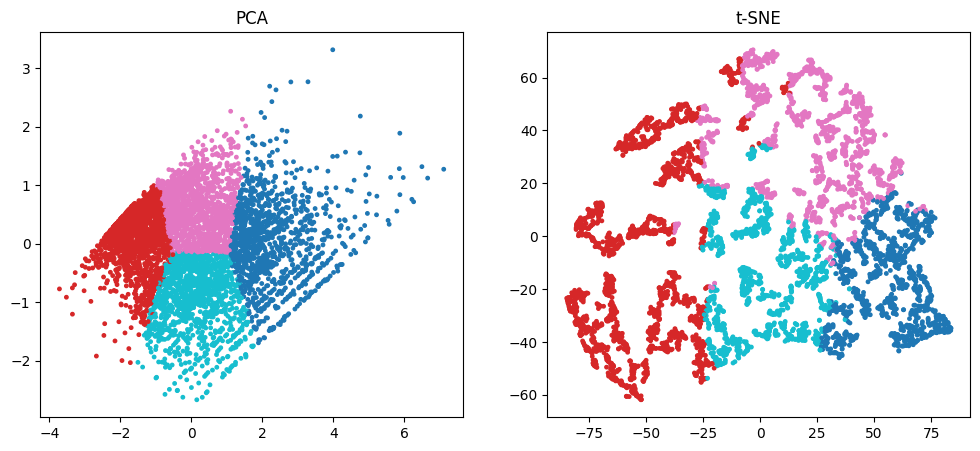

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(*Xp.T, c=rfm.KMeans, s=6, cmap="tab10"); ax[0].set_title("PCA")
ax[1].scatter(*Xt.T, c=rfm.KMeans, s=6, cmap="tab10"); ax[1].set_title("t-SNE")
plt.show()

In [7]:
# personas
print(rfm.groupby("KMeans")[["R", "F", "M"]].mean().round(1))
print(rfm.KMeans.value_counts())
print("DBSCAN noise:", (rfm.DBSCAN == -1).sum())

            R     F        M
KMeans                      
0        27.4  19.3  11014.4
1       395.9   1.4    325.7
2       227.9   5.1   2002.1
3        28.4   3.0    865.1
KMeans
1    1974
2    1465
3    1251
0    1188
Name: count, dtype: int64
DBSCAN noise: 232
